# Figure S14: eQTL discovery across studies

eQTL credible-set discovery across sample sizes in All of Us, INTERVAL, and TOPMed, with GTEx tissue comparisons and a shared protein-coding gene analysis.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig1_gene_reference](../../preparation/Fig1/00_gene_reference.R): Extract the GENCODE v48 gene records and stable IDs from the raw GTF.
- [s14_discovery](../../preparation/S14/prepare_discovery.R): Count source AoU, GTEx, INTERVAL and TOPMed credible sets; select the shared coding-gene intersection; count cohort samples; fit descriptive curves and prepare GTEx envelopes.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the current EAS study comparisons

Plot the eQTL discovery comparisons. Their nine-point descriptive curves and GTEx reference envelopes are reused. This notebook does not rerun fine-mapping, count participants, or fit a new discovery curve.


In [2]:
base <- "Supplemental Figures/01_Supplemental_drafts/Figure1_eQTL_discovery/v2_with_EAS"
saved <- purrr::map(c("A", "B"), function(id) readRDS(paper_file(file.path(base, paste0("source_", id), "plot.rds"))))
purrr::walk(saved, function(x) {
  stopifnot(inherits(x$plot, "ggplot"), nrow(x$data) == 9L,
            "EAS" %in% x$data$population, nrow(x$gtex) == 50L)
})


## Restore the two discovery panels

Panel A uses all available targets. Panel B uses 10,881 protein-coding genes shared across the three studies. The curves describe study-level discovery and do not provide a causal estimate of sample-size effects. GTEx tissues form the saved reference envelope and are excluded from the nine-point fit.


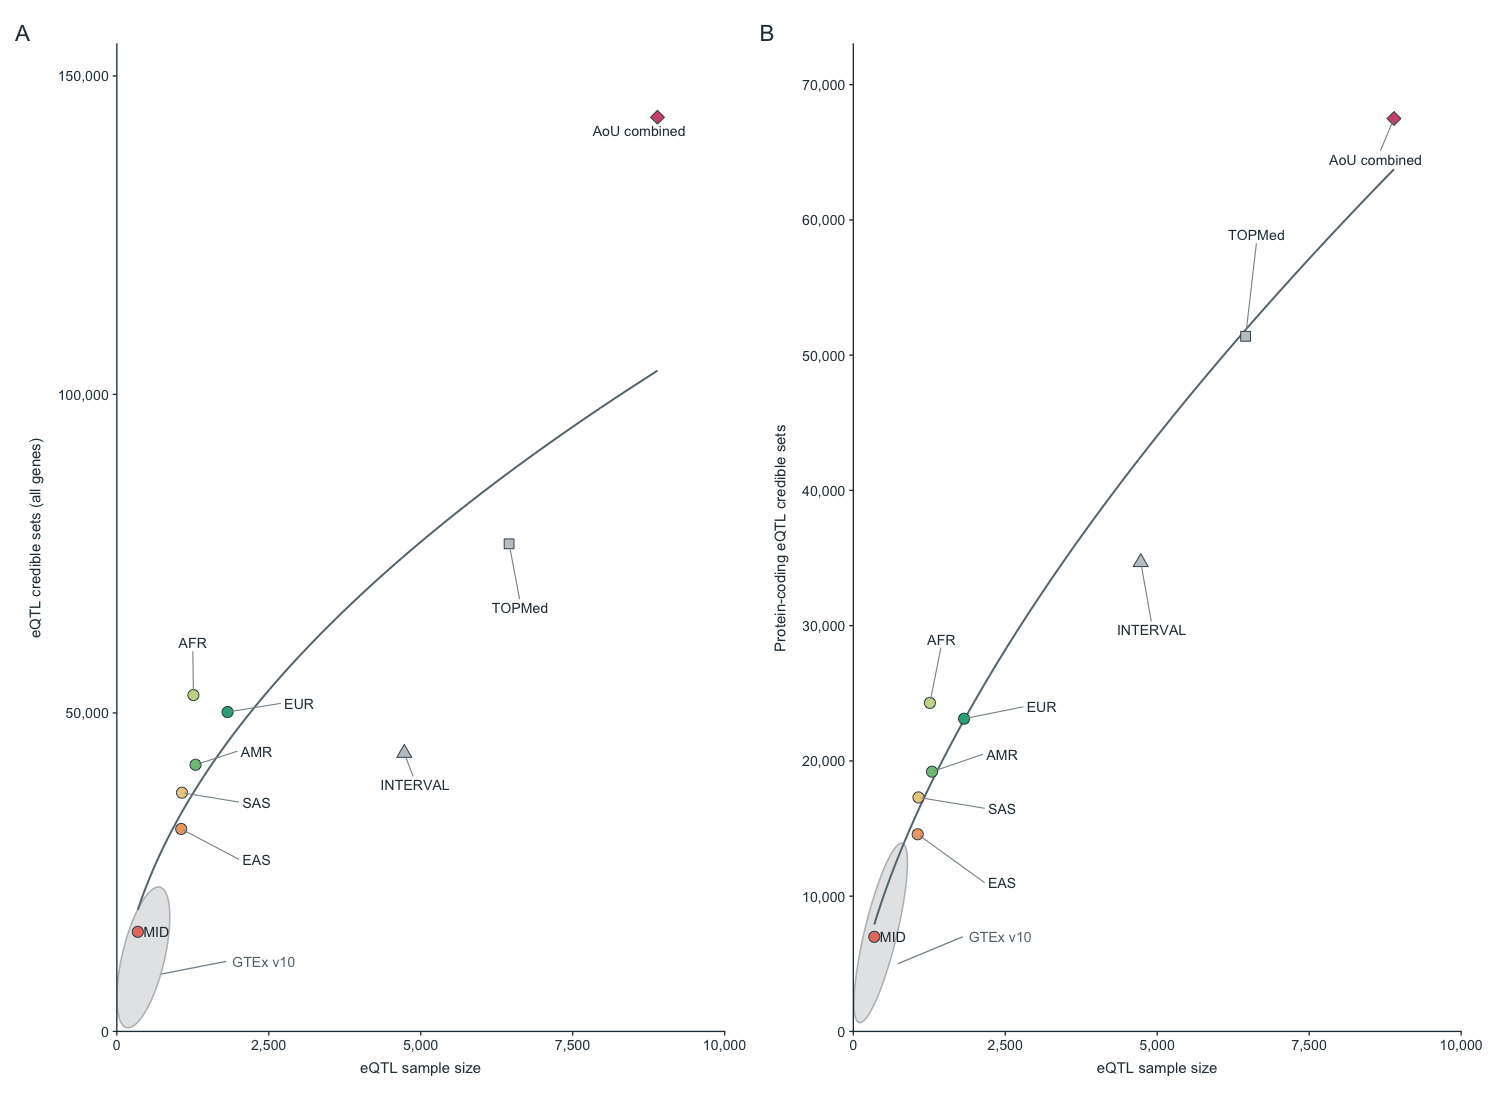

In [3]:
figure <- (saved[[1]]$plot + labs(title = NULL, subtitle = NULL)) +
  (saved[[2]]$plot + labs(title = NULL, subtitle = NULL)) +
  patchwork::plot_layout(nrow = 1) + patchwork::plot_annotation(tag_levels = "A")
print(figure)


## Save aggregate outputs

Save the display and study summaries. No participant identifiers are accessed or exported.


In [4]:
save_plot(figure, "supplements/S14", 184, 85)
readr::write_tsv(purrr::map2_dfr(saved, c("A", "B"), ~mutate(.x$data, panel = .y)),
                 output_file("supplements/S14_study_summaries.tsv"))


Export aggregate plot: supplements/S14
